Using: D:\AgriVision\data\raw\Long 2023 Plant Path 999 photos\BrownRust1018.png
File exists: True


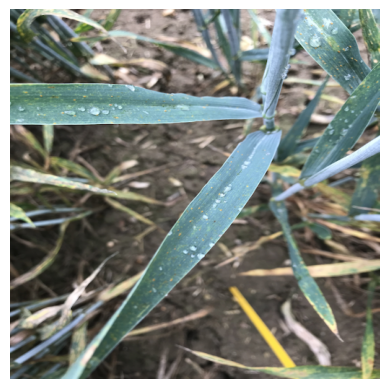

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# pick the first BrownRust image from the dataset
path = next(Path(r"D:\AgriVision\data\raw").rglob("BrownRust*.png"))
print("Using:", path)
print("File exists:", path.exists())

img = cv2.imread(str(path))
if img is None:
    raise FileNotFoundError("Could not read the image. Check the file name and folder.")

img = cv2.resize(img, (512, 512))
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(rgb)
plt.axis("off")
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def estimate_severity(path):
    img = cv2.imread(str(path))
    img = cv2.resize(img, (512, 512))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 1. green pixels (healthy leaf tissue)
    green = cv2.inRange(hsv, (35, 60, 50), (85, 255, 255))

    # 2. leaf region: merge green pixels, keep only large blobs
    kernel = np.ones((15, 15), np.uint8)
    leaf = cv2.morphologyEx(green, cv2.MORPH_CLOSE, kernel)
    leaf = cv2.dilate(leaf, np.ones((9, 9), np.uint8))

    n, labels, stats, _ = cv2.connectedComponentsWithStats(leaf)
    leaf_mask = np.zeros_like(leaf)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] > 3000:
            leaf_mask[labels == i] = 255

    # 3. diseased = yellow/orange pixels, only inside the leaf region
    diseased = cv2.inRange(hsv, (10, 70, 90), (34, 255, 255))
    diseased = cv2.bitwise_and(diseased, leaf_mask)

    healthy_px = int(np.count_nonzero(green))
    diseased_px = int(np.count_nonzero(diseased))
    leaf_px = healthy_px + diseased_px
    severity = 100 * diseased_px / leaf_px if leaf_px else 0.0

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    overlay = rgb.copy()
    overlay[green > 0] = (0, 200, 0)
    overlay[diseased > 0] = (255, 0, 0)
    return severity, rgb, overlay

def show(path):
    sev, rgb, overlay = estimate_severity(path)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(rgb)
    ax[0].set_title(Path(path).name)
    ax[0].axis("off")
    ax[1].imshow(overlay)
    ax[1].set_title(f"Severity: {sev:.1f}%")
    ax[1].axis("off")
    plt.show()

RAW = Path(r"D:\AgriVision\data\raw")
for pattern in ["Healthy*.png", "YellowRust*.png", "BrownRust*.png"]:
    show(next(RAW.rglob(pattern)))

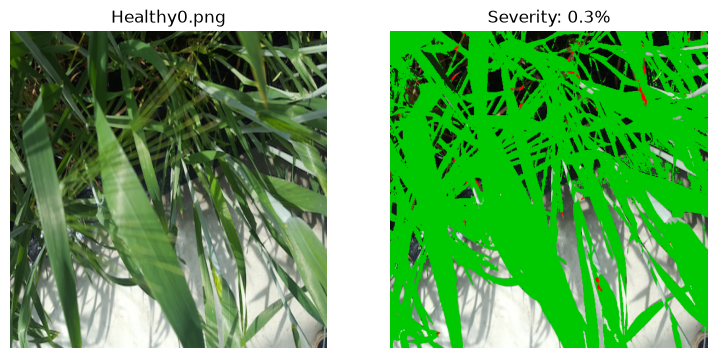

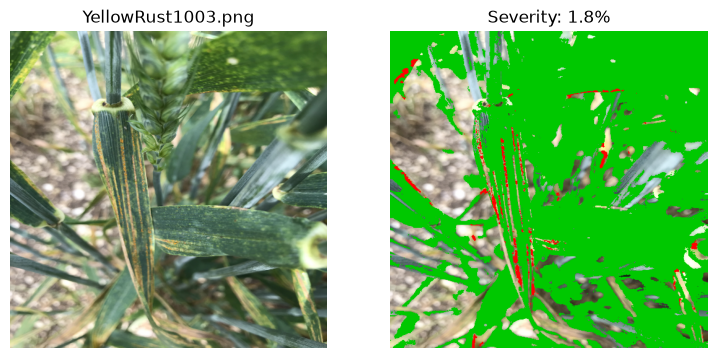

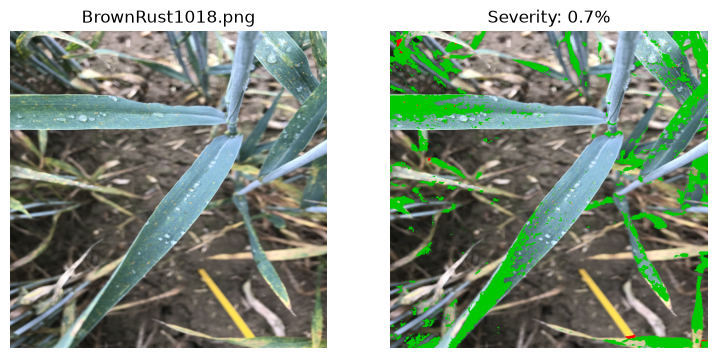

In [4]:
def show(path):
    sev, rgb, overlay = estimate_severity(path)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(rgb); ax[0].set_title(Path(path).name); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title(f"Severity: {sev:.1f}%"); ax[1].axis("off")
    plt.show()

RAW = Path(r"D:\AgriVision\data\raw")
for pattern in ["Healthy*.png", "YellowRust*.png", "BrownRust*.png"]:
    show(next(RAW.rglob(pattern)))